<a href="https://colab.research.google.com/github/Gokulakrishnan1702/deeplearning-lab/blob/main/22AI501.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

ex:1

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training Images : (60000, 28, 28)
Training Labels : (60000,)
Testing Images  : (10000, 28, 28)
Testing Labels  : (10000,)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.9239 - loss: 0.2614 - val_accuracy: 0.9553 - val_loss: 0.1459
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9657 - loss: 0.1135 - val_accuracy: 0.9695 - val_loss: 0.1025
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9766 - loss: 0.0767 - val_accuracy: 0.9714 - val_loss: 0.0970
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.9821 - loss: 0.0565 - val_accuracy: 0.9725 - val_loss: 0.0966
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.9852 - loss: 0.0465 - val_accuracy: 0.9743 - val_loss: 0.0963
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9761 - loss: 0.0821

Testing Accuracy : 0.9761000275611877
Testing Loss     : 0.08210040628910065
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step

Predicted Digit : 7
Actual Digit    : 7


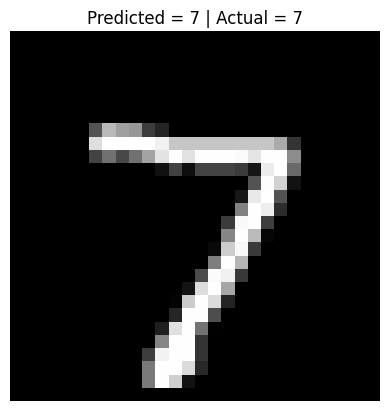

In [1]:
# Import TensorFlow library for deep learning
import tensorflow as tf
# Import the MNIST handwritten digit dataset
from tensorflow.keras.datasets import mnist
# Import Sequential model to build a neural network layer by layer
from tensorflow.keras.models import Sequential
# Import layers used in the neural network
from tensorflow.keras.layers import Dense, Flatten
# Import Matplotlib for displaying images
import matplotlib.pyplot as plt

# -------------------------------------------------------
# Step 1: Load the MNIST Dataset
# -------------------------------------------------------
# Load training and testing data
(x_train, y_train), (x_test, y_test) = mnist.load_data()
# Display the shape of datasets
print("Training Images :", x_train.shape)
print("Training Labels :", y_train.shape)
print("Testing Images  :", x_test.shape)
print("Testing Labels  :", y_test.shape)
# -------------------------------------------------------
# Step 2: Normalize the Images
# -------------------------------------------------------
# Convert pixel values from 0-255 into 0-1
x_train = x_train / 255.0
x_test = x_test / 255.0
# -------------------------------------------------------
# Step 3: Build the Feedforward Neural Network
# -------------------------------------------------------
# Create a Sequential Neural Network
model = Sequential([
# Flatten converts 28x28 image into a 784-dimensional vector
                     Flatten(input_shape=(28, 28)),
 # First Hidden Layer
    Dense(128, activation='relu'),
    # Second Hidden Layer
    Dense(64, activation='relu'),
    # Output Layer
    # 10 neurons represent digits 0-9
    Dense(10, activation='softmax')
])
# -------------------------------------------------------
# Step 4: Compile the Model
# -------------------------------------------------------
model.compile(
    # Optimizer updates weights
    optimizer='adam',
    # Loss function for multiclass classification
    loss='sparse_categorical_crossentropy',
    # Evaluation metric
    metrics=['accuracy']
)
# Display the architecture
model.summary()
# -------------------------------------------------------
# Step 5: Train the Model
# -------------------------------------------------------
history = model.fit(
    x_train,
    y_train,
    # Number of complete passes through dataset
    epochs=5,

    # Number of samples processed together
    batch_size=32,
    # 20% of training data used for validation
    validation_split=0.2
)
# -------------------------------------------------------
# Step 6: Evaluate the Model
# -------------------------------------------------------
test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test
)
print("\nTesting Accuracy :", test_accuracy)
print("Testing Loss     :", test_loss)
# -------------------------------------------------------
# Step 7: Predict a Test Image
# -------------------------------------------------------
# Predict the first testing image
prediction = model.predict(x_test[:1])
# Find the predicted digit
predicted_digit = prediction.argmax()
print("\nPredicted Digit :", predicted_digit)
print("Actual Digit    :", y_test[0])
# -------------------------------------------------------
# Display the Test Image
# -------------------------------------------------------
plt.imshow(x_test[0], cmap='gray')
plt.title("Predicted = {} | Actual = {}".format(predicted_digit, y_test[0]))
plt.axis("off")
plt.show()

ex:2


MobileNetV2 Model Loaded Successfully


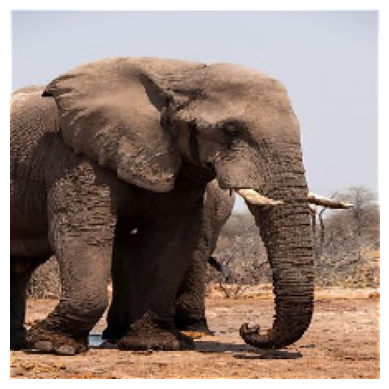

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
35363/35363 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

Top 3 Predictions:

Prediction 1
Class Name : African_elephant
Confidence : 39.96 %

Prediction 2
Class Name : tusker
Confidence : 37.89 %

Prediction 3
Class Name : Indian_elephant
Confidence : 8.89 %



In [ ]:
# ------------------------------------------------------------
# CNN Image Classification using MobileNetV2 (ImageNet)
# ------------------------------------------------------------
# Import required libraries
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.applications.mobilenet_v2 import decode_predictions
from tensorflow.keras.preprocessing import image

# ------------------------------------------------------------
# Step 1: Load Pre-trained CNN Model
# ------------------------------------------------------------
model = MobileNetV2(weights='imagenet')
print("MobileNetV2 Model Loaded Successfully")
# ------------------------------------------------------------
# Step 2: Load Input Image
# ------------------------------------------------------------
# Replace with your image file
img_path = "elephent.jpg"
img = image.load_img(img_path, target_size=(224,224))
# Display image
plt.imshow(img)
plt.axis("off")
plt.show()
# ------------------------------------------------------------
# Step 3: Convert Image into Array
# ------------------------------------------------------------
img_array = image.img_to_array(img)
# Add batch dimension
img_array = np.expand_dims(img_array, axis=0)
# ------------------------------------------------------------
# Step 4: Preprocess Image
# ------------------------------------------------------------
img_array = preprocess_input(img_array)

# ------------------------------------------------------------
# Step 5: Predict Image Class
# ------------------------------------------------------------
predictions = model.predict(img_array)
# ------------------------------------------------------------
# Step 6: Decode Predictions
# ------------------------------------------------------------
decoded = decode_predictions(predictions, top=3)[0]
# ------------------------------------------------------------
# Step 7: Display Results
# ------------------------------------------------------------
print("\nTop 3 Predictions:\n")
for i, pred in enumerate(decoded):
    print("Prediction", i+1)
    print("Class Name :", pred[1])
    print("Confidence :", round(pred[2]*100,2), "%")
    print()


ex:3


Pre-trained SSD MobileNet V2 Loaded Successfully
KeysView(_SignatureMap({'serving_default': <ConcreteFunction (*, input_tensor: TensorSpec(shape=(1, None, None, 3), dtype=tf.uint8, name='input_tensor')) -> Dict[['raw_detection_boxes', TensorSpec(shape=(1, 1917, 4), dtype=tf.float32, name='raw_detection_boxes')], ['detection_multiclass_scores', TensorSpec(shape=(1, 100, 91), dtype=tf.float32, name='detection_multiclass_scores')], ['detection_classes', TensorSpec(shape=(1, 100), dtype=tf.float32, name='detection_classes')], ['detection_boxes', TensorSpec(shape=(1, 100, 4), dtype=tf.float32, name='detection_boxes')], ['raw_detection_scores', TensorSpec(shape=(1, 1917, 91), dtype=tf.float32, name='raw_detection_scores')], ['num_detections', TensorSpec(shape=(1,), dtype=tf.float32, name='num_detections')], ['detection_anchor_indices', TensorSpec(shape=(1, 100), dtype=tf.float32, name='detection_anchor_indices')], ['detection_scores', TensorSpec(shape=(1, 100), dtype=tf.float32, name='detect

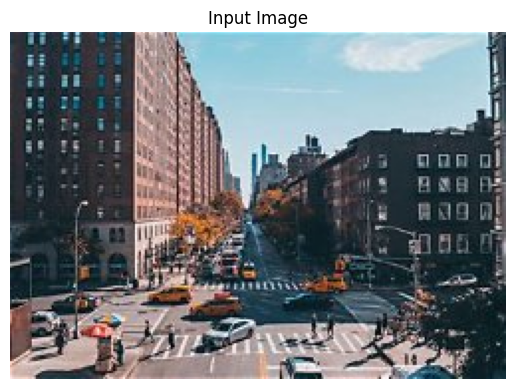


Detected Objects

Object ID : 1
Confidence : 52.81 %
Bounding Box : [0.8542832  0.17724131 0.9732189  0.22450556]



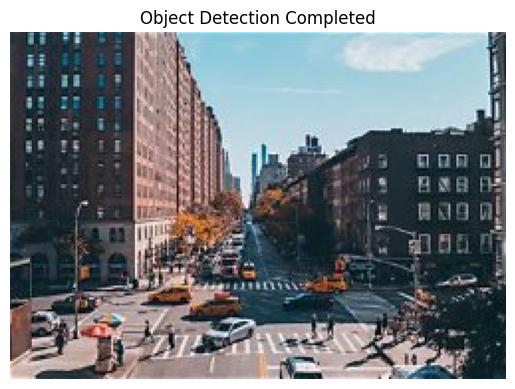

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import tensorflow_hub as hub
from PIL import Image
import os       # Added for checking file existence

# --------------------------------------------------------
# Step 1 : Load Pre-trained Object Detection Model
# --------------------------------------------------------
model = hub.load("https://tfhub.dev/tensorflow/ssd_mobilenet_v2/2")
print("Pre-trained SSD MobileNet V2 Loaded Successfully")
print(model.signatures.keys())
# --------------------------------------------------------
# Step 2 : Load Image
# --------------------------------------------------------
image_path = "/content/sample_data/street.jpg" # Explicitly set to the correct path

# The file is confirmed to be in sample_data, so no download logic is needed.
if not os.path.exists(image_path):
    # This part should ideally not be reached if the file is present as stated.
    # If it is, it indicates a deeper issue or incorrect path.
    raise FileNotFoundError(f"The file '{image_path}' was not found. Please ensure it exists in the specified path.")

img = Image.open(image_path)
img = img.convert("RGB")
# Display original image
plt.imshow(img)
plt.title("Input Image")
plt.axis("off")
plt.show()
# --------------------------------------------------------
# Step 3 : Preprocess Image
# --------------------------------------------------------
img_array = np.array(img)
input_tensor = tf.convert_to_tensor(img_array)
input_tensor = input_tensor[tf.newaxis, ...]
# --------------------------------------------------------
# Step 4 : Perform Object Detection
# --------------------------------------------------------
detector = model.signatures["serving_default"]
results = detector(input_tensor)
# --------------------------------------------------------
# Step 5 : Extract Detection Results
# --------------------------------------------------------
boxes = results["detection_boxes"][0].numpy()
classes = results["detection_classes"][0].numpy().astype(int)
scores = results["detection_scores"][0].numpy()
# --------------------------------------------------------
# Step 6 : Display Detection Results
# --------------------------------------------------------
print("\nDetected Objects\n")
for i in range(len(scores)):
    if scores[i] > 0.50:
        print("Object ID :", classes[i])
        print("Confidence :", round(scores[i]*100,2), "%")
        print("Bounding Box :", boxes[i])
        print()
# --------------------------------------------------------
# Step 7 : Display Image
# --------------------------------------------------------
plt.imshow(img)
plt.title("Object Detection Completed")
plt.axis("off")
plt.show()

e

ex:4


Epoch 1/20


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0121
Epoch 2/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 8.1386e-04
Epoch 3/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 5.9362e-04
Epoch 4/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 6.0539e-04
Epoch 5/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 5.0566e-04
Epoch 6/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 4.7938e-04
Epoch 7/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 4.9185e-04
Epoch 8/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 4.6872e-04
Epoch 9/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 4.5168e-04
Epoch 10/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 4.4001e-04
Epoch 11/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 4.3518e-04
Epoch 12/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 4.1181e-04
Epoch 13/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 4.0544e-04
Epoch 14/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 3.8830e-04
Epoch 15/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s

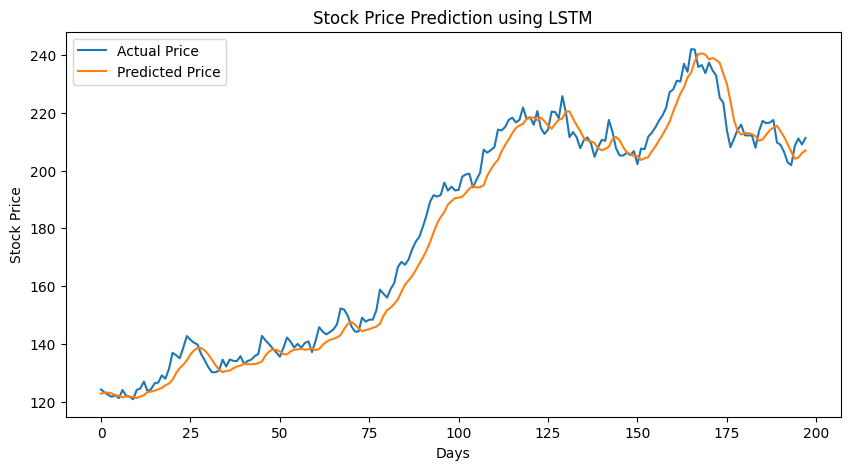

In [ ]:

# -------------------------------------------------------
# LSTM for Stock Price Prediction
# -------------------------------------------------------
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
# -------------------------------------------------------
# Step 1 : Load Dataset
# -------------------------------------------------------
data = pd.read_csv("stock_data.csv")
# Select only the Closing Price
dataset = data[['Close']].values
# -------------------------------------------------------
# Step 2 : Normalize Data
# -------------------------------------------------------
scaler = MinMaxScaler(feature_range=(0,1))
dataset_scaled = scaler.fit_transform(dataset)
# -------------------------------------------------------
# Step 3 : Create Time Series Sequences
# -------------------------------------------------------
X = []
Y = []
time_step = 10
for i in range(len(dataset_scaled)-time_step):
    X.append(dataset_scaled[i:i+time_step])
    Y.append(dataset_scaled[i+time_step])
X = np.array(X)
Y = np.array(Y)
# Split into Training and Testing data
split = int(len(X)*0.8)
X_train = X[:split]
X_test = X[split:]
Y_train = Y[:split]
Y_test = Y[split:]
# -------------------------------------------------------
# Step 4 : Build LSTM Model
# -------------------------------------------------------
model = Sequential()
model.add(LSTM(50, activation='relu',
               input_shape=(time_step,1)))
model.add(Dense(1))
# -------------------------------------------------------
# Step 5 : Compile and Train
# -------------------------------------------------------
model.compile(
    optimizer='adam',
    loss='mean_squared_error'
)
model.fit(
    X_train,
    Y_train,
    epochs=20,
    batch_size=16
)
# -------------------------------------------------------
# Step 6 : Predict Stock Prices
# -------------------------------------------------------
predicted = model.predict(X_test)
predicted = scaler.inverse_transform(predicted)

actual = scaler.inverse_transform(Y_test)
# -------------------------------------------------------
# Step 7 : Plot Results
# -------------------------------------------------------
plt.figure(figsize=(10,5))
plt.plot(actual,label="Actual Price")
plt.plot(predicted,label="Predicted Price")
plt.xlabel("Days")
plt.ylabel("Stock Price")
plt.title("Stock Price Prediction using LSTM")
plt.legend()
plt.show()


ex:5

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch: 0
Epoch: 100
Epoch: 200
Epoch: 300
Epoch: 400
Epoch: 500
Epoch: 600
Epoch: 700
Epoch: 800
Epoch: 900


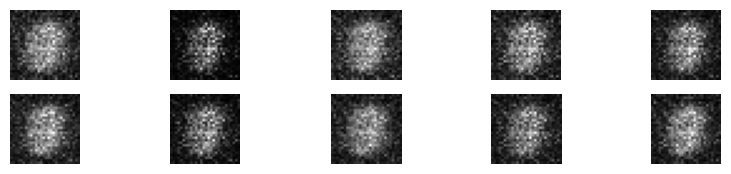

In [ ]:
# --------------------------------------------------------
# Generative Adversarial Network (GAN) using MNIST
# --------------------------------------------------------
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LeakyReLU, Reshape, Flatten
from tensorflow.keras.optimizers import Adam
# --------------------------------------------------------
# Step 1 : Load Dataset
# --------------------------------------------------------
(X_train, _), (_, _) = mnist.load_data()
# --------------------------------------------------------
# Step 2 : Preprocess Dataset
# --------------------------------------------------------
X_train = X_train.astype('float32')
X_train = (X_train - 127.5) / 127.5
X_train = X_train.reshape(X_train.shape[0], 784)
# --------------------------------------------------------
# Step 3 : Generator
# --------------------------------------------------------
generator = Sequential()
generator.add(Dense(256, input_dim=100))
generator.add(LeakyReLU(0.2))
generator.add(Dense(512))
generator.add(LeakyReLU(0.2))
generator.add(Dense(1024))
generator.add(LeakyReLU(0.2))
generator.add(Dense(784, activation='tanh'))
# --------------------------------------------------------
# Step 4 : Discriminator
# --------------------------------------------------------
discriminator = Sequential()
discriminator.add(Dense(1024, input_dim=784))
discriminator.add(LeakyReLU(0.2))
discriminator.add(Dense(512))
discriminator.add(LeakyReLU(0.2))

discriminator.add(Dense(256))
discriminator.add(LeakyReLU(0.2))
discriminator.add(Dense(1, activation='sigmoid'))
discriminator.compile(
    loss='binary_crossentropy',
    optimizer=Adam(0.0002),
    metrics=['accuracy']
)
# --------------------------------------------------------
# Step 5 : GAN Model
# --------------------------------------------------------
discriminator.trainable = False
gan = Sequential()
gan.add(generator)
gan.add(discriminator)
gan.compile(
    loss='binary_crossentropy',
    optimizer=Adam(0.0002)
)
# --------------------------------------------------------
# Step 6 : Train GAN
# --------------------------------------------------------
epochs = 1000
batch_size = 64

for epoch in range(epochs):
    # Real Images
    idx = np.random.randint(0, X_train.shape[0], batch_size)
    real_images = X_train[idx]
    # Fake Images
    noise = np.random.normal(0,1,(batch_size,100))
    fake_images = generator.predict(noise, verbose=0)
    # Labels
    real_labels = np.ones((batch_size,1))
    fake_labels = np.zeros((batch_size,1))
    # Train Discriminator
    discriminator.trainable = True
    discriminator.train_on_batch(real_images, real_labels)
    discriminator.train_on_batch(fake_images, fake_labels)
    # Train Generator
    discriminator.trainable = False
    noise = np.random.normal(0,1,(batch_size,100))
    gan.train_on_batch(noise, real_labels)
    if epoch % 100 == 0:
        print("Epoch:", epoch)
# --------------------------------------------------------
# Step 7 : Generate Images
# --------------------------------------------------------
noise = np.random.normal(0,1,(10,100))
generated = generator.predict(noise, verbose=0)
generated = generated.reshape(10,28,28)
plt.figure(figsize=(10,2))
for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(generated[i], cmap='gray')
    plt.axis("off")
plt.show()


ex:6

In [ ]:
# --------------------------------------------------------
# Q-Learning using OpenAI Gym (FrozenLake-v1)
# --------------------------------------------------------
import gymnasium as gym
import numpy as np
# --------------------------------------------------------
# Step 1 : Create Environment
# --------------------------------------------------------
env = gym.make("FrozenLake-v1", is_slippery=False)
# --------------------------------------------------------
# Step 2 : Initialize Q-Table
# --------------------------------------------------------
state_size = env.observation_space.n
action_size = env.action_space.n
Q = np.zeros((state_size, action_size))
learning_rate = 0.8
discount_factor = 0.95
epsilon = 1.0
epsilon_decay = 0.995
epsilon_min = 0.01
episodes = 2000
max_steps = 100
# --------------------------------------------------------
# Step 3 : Training
# --------------------------------------------------------
for episode in range(episodes):
    state, info = env.reset()
    done = False
    for step in range(max_steps):
        # Exploration or Exploitation
        if np.random.rand() < epsilon:
            action = env.action_space.sample()
        else:
            action = np.argmax(Q[state])
        # ------------------------------------------------
        # Step 4 : Execute Action
        # ------------------------------------------------
        next_state, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated
        # ------------------------------------------------
        # Step 5 : Update Q-table
        # ------------------------------------------------
        Q[state, action] = Q[state, action] + learning_rate * (
            reward +
            discount_factor * np.max(Q[next_state]) -
            Q[state, action]
        )
        state = next_state
        if done:
            break
    epsilon = max(epsilon * epsilon_decay, epsilon_min)
# --------------------------------------------------------
# Step 6 : Training Completed
# --------------------------------------------------------
print("Training Completed Successfully")
print("\nLearned Q-Table\n")
print(Q)
# --------------------------------------------------------
# Step 7 : Testing
# --------------------------------------------------------
print("\nTesting Agent\n")
state, info = env.reset()
done = False
total_reward = 0
while not done:
    action = np.argmax(Q[state])
    next_state, reward, terminated, truncated, info = env.step(action)
    total_reward += reward
    state = next_state
    done = terminated or truncated
print("Total Reward :", total_reward)
env.close()


Training Completed Successfully

Learned Q-Table

[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]

Testing Agent

Total Reward : 0


ex:7a
italicized text

In [ ]:
# -------------------------------------------------------
# Sentiment Analysis using LSTM
# -------------------------------------------------------
import tensorflow as tf
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
# -------------------------------------------------------
# Step 1 : Load Dataset
# -------------------------------------------------------
vocab_size = 10000

(X_train, Y_train), (X_test, Y_test) = imdb.load_data(num_words=vocab_size)
# -------------------------------------------------------
# Step 2 : Pad Sequences
# -------------------------------------------------------
max_length = 200
X_train = pad_sequences(X_train, maxlen=max_length)
X_test = pad_sequences(X_test, maxlen=max_length)
# -------------------------------------------------------
# Step 3 : Build LSTM Model
# -------------------------------------------------------
model = Sequential()
model.add(Embedding(vocab_size,128,input_length=max_length))
model.add(LSTM(64))
model.add(Dense(1,activation='sigmoid'))
# -------------------------------------------------------
# Step 4 : Compile Model
# -------------------------------------------------------
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)
# -------------------------------------------------------
# Step 5 : Train Model
# -------------------------------------------------------

model.fit(
    X_train,
    Y_train,
    epochs=3,
    batch_size=64,
    validation_split=0.2
)
# -------------------------------------------------------
# Step 6 : Evaluate
# -------------------------------------------------------
loss,accuracy = model.evaluate(X_test,Y_test)
print("\nTest Accuracy :",accuracy)
# -------------------------------------------------------
# Step 7 : Predict
# -------------------------------------------------------
prediction = model.predict(X_test[:5])
print("\nPrediction Probabilities")
print(prediction)


17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 87s 270ms/step - accuracy: 0.7927 - loss: 0.4385 - val_accuracy: 0.8426 - val_loss: 0.3740
Epoch 2/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 102s 325ms/step - accuracy: 0.8939 - loss: 0.2661 - val_accuracy: 0.8664 - val_loss: 0.3529
Epoch 3/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 80s 255ms/step - accuracy: 0.9221 - loss: 0.2068 - val_accuracy: 0.8598 - val_loss: 0.3508
782/782 ━━━━━━━━━━━━━━━━━━━━ 26s 33ms/step - accuracy: 0.8575 - loss: 0.3524

Test Accuracy : 0.8575199842453003
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 194ms/step

Prediction Probabilities
[[0.11577019]
 [0.98935777]
 [0.8749369 ]
 [0.42751598]
 [0.99946296]]


ex:7b

In [ ]:
# -------------------------------------------------------
# Text Classification using Reuters Dataset
# -------------------------------------------------------
import tensorflow as tf
from tensorflow.keras.datasets import reuters
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, GlobalAveragePooling1D, Dense
# -------------------------------------------------------
# Step 1 : Load Dataset
# -------------------------------------------------------
vocab_size = 10000

(X_train, Y_train), (X_test, Y_test) = reuters.load_data(num_words=vocab_size)
# -------------------------------------------------------
# Step 2 : Pad Sequences
# -------------------------------------------------------
max_length = 200
X_train = pad_sequences(X_train, maxlen=max_length)
X_test = pad_sequences(X_test, maxlen=max_length)
# -------------------------------------------------------
# Step 3 : Build Model
# -------------------------------------------------------
model = Sequential()
model.add(Embedding(vocab_size,128,input_length=max_length))
model.add(GlobalAveragePooling1D())
model.add(Dense(64,activation='relu'))
model.add(Dense(46,activation='softmax'))
# -------------------------------------------------------
# Step 4 : Compile
# -------------------------------------------------------
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
# -------------------------------------------------------
# Step 5 : Train
# -------------------------------------------------------
model.fit(
    X_train,
    Y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2
)
# -------------------------------------------------------
# Step 6 : Evaluate
# -------------------------------------------------------
loss,accuracy=model.evaluate(X_test,Y_test)
print("Test Accuracy :",accuracy)
# -------------------------------------------------------
# Step 7 : Predict
# -------------------------------------------------------
prediction=model.predict(X_test[:5])
print("Predicted Categories")
print(prediction.argmax(axis=1))


2110848/2110848 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


113/113 ━━━━━━━━━━━━━━━━━━━━ 5s 36ms/step - accuracy: 0.3960 - loss: 2.4495 - val_accuracy: 0.4697 - val_loss: 2.0972
Epoch 2/5
113/113 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - accuracy: 0.4894 - loss: 1.9954 - val_accuracy: 0.5109 - val_loss: 1.8839
Epoch 3/5
113/113 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - accuracy: 0.5461 - loss: 1.8029 - val_accuracy: 0.5854 - val_loss: 1.7005
Epoch 4/5
113/113 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - accuracy: 0.6277 - loss: 1.5971 - val_accuracy: 0.6628 - val_loss: 1.5153
Epoch 5/5
113/113 ━━━━━━━━━━━━━━━━━━━━ 5s 25ms/step - accuracy: 0.6785 - loss: 1.4042 - val_accuracy: 0.6828 - val_loss: 1.3730
71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6808 - loss: 1.4308
Test Accuracy : 0.6807658076286316
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step
Predicted Categories
[ 3  1  1  4 16]


ex:7c

In [ ]:
# -------------------------------------------------------
# Language Translation using Transformers
# -------------------------------------------------------
from transformers import AutoTokenizer
from transformers import AutoModelForSeq2SeqLM
# -------------------------------------------------------
# Step 1 : Load Pre-trained Model
# -------------------------------------------------------
model_name = "Helsinki-NLP/opus-mt-en-fr"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSeq2SeqLM.from_pretrained(model_name)
# -------------------------------------------------------
# Step 2 : Input Sentence
# -------------------------------------------------------

text = "Artificial Intelligence is changing the world."
# -------------------------------------------------------
# Step 3 : Tokenize Input
# -------------------------------------------------------
inputs = tokenizer(text, return_tensors="pt")
# -------------------------------------------------------
# Step 4 : Translate
# -------------------------------------------------------
translated = model.generate(**inputs)
# -------------------------------------------------------
# Step 5 : Decode Output
# -------------------------------------------------------
output = tokenizer.decode(translated[0], skip_special_tokens=True)
# -------------------------------------------------------
# Step 6 : Display Output
# -------------------------------------------------------
print("English Sentence:")
print(text)
print()
print("French Translation:")
print(output)



config.json:   0%|          | 0.00/1.42k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/42.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/778k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/802k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.34M [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  301MB            

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

model.safetensors: downloading bytes:           |  0.00B            

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

English Sentence:
Artificial Intelligence is changing the world.

French Translation:
L'intelligence artificielle change le monde.


ex:8

In [ ]:


# -------------------------------------------------------
# Deep Learning Recommendation System
# Collaborative Filtering using Embeddings
# -------------------------------------------------------
import pandas as pd
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.layers import Input
from tensorflow.keras.layers import Embedding
from tensorflow.keras.layers import Flatten
from tensorflow.keras.layers import Dot
from tensorflow.keras.models import Model
# -------------------------------------------------------
# Step 1 : Load Dataset
# -------------------------------------------------------
data = pd.read_csv("ratings.csv")
print(data.head())
# -------------------------------------------------------
# Step 2 : Encode Users and Movies
# -------------------------------------------------------
user_encoder = LabelEncoder()
movie_encoder = LabelEncoder()
data["user"] = user_encoder.fit_transform(data["userId"])
data["movie"] = movie_encoder.fit_transform(data["movieId"])
num_users = data["user"].nunique()
num_movies = data["movie"].nunique()
# -------------------------------------------------------
# Step 3 : Split Dataset
# -------------------------------------------------------
X = data[["user","movie"]]
y = data["rating"]
X_train,X_test,y_train,y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
# -------------------------------------------------------
# Step 4 : Build Recommendation Model
# -------------------------------------------------------
user_input = Input(shape=(1,))
movie_input = Input(shape=(1,))
user_embedding = Embedding(
    input_dim=num_users,
    output_dim=50
)(user_input)
movie_embedding = Embedding(
    input_dim=num_movies,
    output_dim=50
)(movie_input)
user_vector = Flatten()(user_embedding)
movie_vector = Flatten()(movie_embedding)
output = Dot(axes=1)([user_vector,movie_vector])
model = Model(
    inputs=[user_input,movie_input],
    outputs=output
)
# -------------------------------------------------------
# Step 5 : Compile and Train
# -------------------------------------------------------
model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)
model.fit(
    [X_train["user"],X_train["movie"]],
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.2
)
# -------------------------------------------------------
# Step 6 : Evaluate
# -------------------------------------------------------
loss,mae = model.evaluate(
    [X_test["user"],X_test["movie"]],
    y_test
)
print("\nMean Absolute Error :",mae)
# -------------------------------------------------------
# Step 7 : Recommend Movies
# -------------------------------------------------------
user_id = 0
movies = np.arange(num_movies)
users = np.full(num_movies,user_id)
predictions = model.predict([users,movies])
top_movies = np.argsort(predictions.flatten())[::-1][:10]
print("\nTop Recommended Movie IDs")
original_movie_ids = movie_encoder.inverse_transform(top_movies)
print(original_movie_ids)



   userId  movieId  rating
0       1       10     3.0
1       1       14     3.0
2       1       23     2.5
3       1       31     3.0
4       1       39     5.0
Epoch 1/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 13.0085 - mae: 3.4969 - val_loss: 13.0030 - val_mae: 3.5015
Epoch 2/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 12.9313 - mae: 3.4861 - val_loss: 12.9320 - val_mae: 3.4913
Epoch 3/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 12.6235 - mae: 3.4420 - val_loss: 12.4230 - val_mae: 3.4174
Epoch 4/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 11.4101 - mae: 3.2604 - val_loss: 10.5765 - val_mae: 3.1345
Epoch 5/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 8.5947 - mae: 2.7885 - val_loss: 7.1810 - val_mae: 2.5304
Epoch 6/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 4.9533 - mae: 2.0348 - val_loss: 3.7795 - val_mae: 1.7421
Epoch 7/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 2.2840 - mae: 1.2846 - val_loss: 1.8329 - val_mae: 1.1352
Epoc

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step

Top Recommended Movie IDs
[ 75  27 132 106  72 153 150 163   5  93]


ex:9

In [ ]:
# ---------------------------------------------------------
# Speech Recognition using CNN
# Google Speech Commands Dataset
# ---------------------------------------------------------
import tensorflow as tf
import numpy as np
import pathlib
# ---------------------------------------------------------
# Step 1 : Download Dataset
# ---------------------------------------------------------
DATASET_URL = "http://storage.googleapis.com/download.tensorflow.org/data/mini_speech_commands.zip"

data_dir = tf.keras.utils.get_file(
    'mini_speech_commands',
    origin=DATASET_URL,
    extract=True,
    cache_dir='.'
)
data_dir = pathlib.Path(data_dir).with_suffix('')
print(data_dir)
print(list(data_dir.iterdir()))
print("Dataset Location :", data_dir)
# ---------------------------------------------------------
# Step 2 : Load Dataset
# ---------------------------------------------------------
train_ds, val_ds = tf.keras.utils.audio_dataset_from_directory(
   ## directory=data_dir,
    directory=data_dir / "mini_speech_commands",
    batch_size=32,
    validation_split=0.2,
    seed=123,
    output_sequence_length=16000,
    subset='both'
)
label_names = np.array(train_ds.class_names)
print("Classes")
print(label_names)

# ---------------------------------------------------------
# Step 3 : Convert Audio into Spectrogram
# ---------------------------------------------------------
def get_spectrogram(audio):
    audio = tf.squeeze(audio, axis=-1)
    spectrogram = tf.signal.stft(
        audio,
        frame_length=255,
        frame_step=128
    )
    spectrogram = tf.abs(spectrogram)
    return spectrogram
    spectrogram = tf.abs(spectrogram)
    spectrogram = spectrogram[...,tf.newaxis]
    return spectrogram
def make_spec(audio,label):
    return get_spectrogram(audio),label
train_ds = train_ds.map(make_spec)
val_ds = val_ds.map(make_spec)
# ---------------------------------------------------------
# Step 4 : Build CNN Model
# ---------------------------------------------------------
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(124,129,1)),
    tf.keras.layers.Conv2D(
        32,(3,3),activation='relu'),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(
        64,(3,3),activation='relu'),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Flatten(),
   tf.keras.layers.Dense(
        128,
        activation='relu'),
    tf.keras.layers.Dense(
        len(label_names),
        activation='softmax')
])
# ---------------------------------------------------------
# Step 5 : Compile and Train
# ---------------------------------------------------------
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)
# ---------------------------------------------------------
# Step 6 : Evaluate
# ---------------------------------------------------------
loss,accuracy = model.evaluate(val_ds)
print("\nValidation Accuracy :",accuracy)
# ---------------------------------------------------------
# Step 7 : Prediction
# ---------------------------------------------------------
for spectrogram,label in val_ds.take(1):
    prediction = model.predict(spectrogram)
    predicted = np.argmax(prediction[0])
    print("\nPredicted Word :",label_names[predicted])
    print("Actual Word :",label_names[label[0]])


182082353/182082353 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
datasets/mini_speech_commands
[PosixPath('datasets/mini_speech_commands/__MACOSX'), PosixPath('datasets/mini_speech_commands/mini_speech_commands')]
Dataset Location : datasets/mini_speech_commands
Found 8000 files belonging to 8 classes.
Using 6400 files for training.
Using 1600 files for validation.
Classes
['down' 'go' 'left' 'no' 'right' 'stop' 'up' 'yes']
Epoch 1/5
200/200 ━━━━━━━━━━━━━━━━━━━━ 192s 935ms/step - accuracy: 0.5709 - loss: 1.3435 - val_accuracy: 0.7306 - val_loss: 0.8505
Epoch 2/5
200/200 ━━━━━━━━━━━━━━━━━━━━ 153s 763ms/step - accuracy: 0.8214 - loss: 0.5506 - val_accuracy: 0.8100 - val_loss: 0.6462
Epoch 3/5
200/200 ━━━━━━━━━━━━━━━━━━━━ 194s 971ms/step - accuracy: 0.9039 - loss: 0.3113 - val_accuracy: 0.8244 - val_loss: 0.7088
Epoch 4/5
200/200 ━━━━━━━━━━━━━━━━━━━━ 159s 793ms/step - accuracy: 0.9231 - loss: 0.2478 - val_accuracy: 0.8356 - val_loss: 0.6382
Epoch 5/5
200/200 ━━━━━━━━━━━━━━━━━━━━ 160s 798ms/step - acc

ex:10

In [ ]:
# -------------------------------------------------------
# Deep Q Network (DQN)
# OpenAI Gym - CartPole-v1
# -------------------------------------------------------
import gymnasium as gym
import numpy as np
import random
from collections import deque
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
# -------------------------------------------------------
# Step 1 : Create Environment
# -------------------------------------------------------
env = gym.make("CartPole-v1")
#state_size = env.observation_space.shape[0]
state_size = int(env.observation_space.shape[0])
# action_size = env.action_space.n
action_size = int(env.action_space.n)
# -------------------------------------------------------
# Step 2 : Build DQN
# -------------------------------------------------------
model = Sequential([
    tf.keras.layers.Input(shape=(state_size,)),
    Dense(24, activation='relu'),
    Dense(24, activation='relu'),
    Dense(int(action_size), activation='linear')
])
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mse'
)
memory = deque(maxlen=2000)
gamma = 0.95
epsilon = 1.0
epsilon_decay = 0.995
epsilon_min = 0.01
batch_size = 32
episodes = 100
# -------------------------------------------------------
# Step 3 : Training
# -------------------------------------------------------
for episode in range(episodes):
    state, info = env.reset()
    state = np.reshape(state, [1, state_size])
    total_reward = 0
    done = False
    while not done:
        # ε-greedy action
        if np.random.rand() < epsilon:
            action = env.action_space.sample()
        else:
            q_values = model.predict(state, verbose=0)
            action = np.argmax(q_values[0])
        # ------------------------------------------------
        # Step 4 : Execute Action
        # ------------------------------------------------
        next_state, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated
        next_state = np.reshape(next_state, [1, state_size])
        memory.append((state, action, reward, next_state, done))
        state = next_state
        total_reward += reward
        # ------------------------------------------------
        # Step 5 : Train Network
        # ------------------------------------------------
        if len(memory) >= batch_size:
            minibatch = random.sample(memory, batch_size)
            for s, a, r, ns, d in minibatch:
                target = r
                if not d:
                    target += gamma * np.max(model.predict(ns, verbose=0)[0])
                target_f = model.predict(s, verbose=0)
                target_f[0][a] = target
                model.fit(s, target_f, epochs=1, verbose=0)
    if epsilon > epsilon_min:
        epsilon *= epsilon_decay
    print("Episode:", episode+1, " Reward:", total_reward)
# -------------------------------------------------------
# Step 6 : Training Completed
# -------------------------------------------------------
print("\nTraining Completed Successfully")
# -------------------------------------------------------
# Step 7 : Testing
# -------------------------------------------------------
state, info = env.reset()

state = np.reshape(state,[1,state_size])
done = False
score = 0
while not done:
    action = np.argmax(model.predict(state,verbose=0)[0])
    next_state, reward, terminated, truncated, info = env.step(action)
    done = terminated or truncated
    state = np.reshape(next_state,[1,state_size])
    score += reward
print("\nFinal Test Reward :", score)
env.close()


Episode: 1  Reward: 14.0
Episode: 2  Reward: 13.0
Episode: 3  Reward: 12.0
Episode: 4  Reward: 23.0
Episode: 5  Reward: 12.0
Episode: 6  Reward: 37.0
Episode: 7  Reward: 37.0
Episode: 8  Reward: 18.0
Episode: 9  Reward: 19.0
Episode: 10  Reward: 19.0
Episode: 11  Reward: 14.0
Episode: 12  Reward: 18.0
Episode: 13  Reward: 40.0
Episode: 14  Reward: 10.0
Episode: 15  Reward: 38.0
Episode: 16  Reward: 39.0
Episode: 17  Reward: 10.0
Episode: 18  Reward: 18.0
Episode: 19  Reward: 16.0
